# Exercise: Four-Asset Portfolios

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("ggplot")

### Exercise 1

Using the following variance-covariance matrix and expected returns (means), determine the standard deviation and mean return of portfolios X and Y.

In [2]:
covariance_matrix = np.array([
    [0.10, 0.01, 0.03, 0.05],
    [0.01, 0.30, 0.06, -0.04],
    [0.03, 0.06, 0.40, 0.02],
    [0.05, -0.04, 0.02, 0.50]
])

print(covariance_matrix)


[[ 0.1   0.01  0.03  0.05]
 [ 0.01  0.3   0.06 -0.04]
 [ 0.03  0.06  0.4   0.02]
 [ 0.05 -0.04  0.02  0.5 ]]


In [3]:
mean_returns = np.array([0.06, 0.08, 0.10, 0.15])

print(mean_returns)


[0.06 0.08 0.1  0.15]


In [4]:
weights_x = np.array([0.2, 0.3, 0.4, 0.1])
weights_y = np.array([0.2, 0.1, 0.1, 0.6])

print(weights_x)
print(weights_y)


[0.2 0.3 0.4 0.1]
[0.2 0.1 0.1 0.6]


**Portfolio return**

$E(\tilde R_p)=\sum_{i=1}^{N}w_iE(\tilde R_i)$

$E(\tilde R_p)=
\begin{pmatrix}w_1 & w_2 & ... & w_N\end{pmatrix}
\begin{pmatrix}\mu_1 \\ \mu_2 \\ ... \\ \mu_N\end{pmatrix}
=\mathbf{w}^T\mathbf{\mu}$

In [5]:
# TO-DO: Calculate the mean return of the two portfolios using matrices
weights_x = np.array([0.2, 0.3, 0.4, 0.1])
weights_y = np.array([0.2, 0.1, 0.1, 0.6])

print(weights_x)
print(weights_y)


[0.2 0.3 0.4 0.1]
[0.2 0.1 0.1 0.6]


In [8]:
mu_x = weights_x @ mean_returns
mu_y = weights_y @ mean_returns

print(f"Mean return of portfolio X: {mu_x:.4f}")
print(f"Mean return of portfolio Y: {mu_y:.4f}")

Mean return of portfolio X: 0.0910
Mean return of portfolio Y: 0.1200


$\sigma^2(\tilde R_p)=
\begin{pmatrix}w_1 & w_2 & ... & w_N\end{pmatrix}
\begin{pmatrix}
\sigma_1^2 & \sigma_{12} & ... & \sigma_{1N} \\
\sigma_{21} & \sigma_2^2 & ... & \sigma_{2N} \\
... & ... & ... & ... \\
\sigma_{N1} & \sigma_{N2} & ... & \sigma_N^2
\end{pmatrix}
\begin{pmatrix}w_1 \\ w_2 \\ ... \\ w_N\end{pmatrix}
=\mathbf{w}^T\mathbf{C}\mathbf{w}$

In [10]:
# Portfolio variances
sigma2_x = weights_x @ covariance_matrix @ weights_x
sigma2_y = weights_y @ covariance_matrix @ weights_y

# Portfolio standard deviations
sigma_x = np.sqrt(sigma2_x)
sigma_y = np.sqrt(sigma2_y)

print(f"Standard deviation of portfolio X: {sigma_x:.4f}")
print(f"Standard deviation of portfolio Y: {sigma_y:.4f}")

Standard deviation of portfolio X: 0.3487
Standard deviation of portfolio Y: 0.4510


---

### Exercise 2

Determine the covariance between portfolios X and Y from their weights and the covariance matrix.

$covar(X,Y)=\mathbf{X}^T\mathbf{C}\mathbf{Y}$

Reasoning behind the formula:

$$
\text{covar}_{XY}
=
\mathbf{w}_X^T
\mathbf{C}
\mathbf{w}_Y
$$

The covariance between two portfolios depends on the weights of each portfolio and on the covariance matrix of the underlying assets.

In [11]:
# TO-DO: Calculate the covariance between portfolios X and Y
covar_XY = weights_x.T @ covariance_matrix @ weights_y

print(f"Covariance between X and Y: {covar_XY:.4f}")


Covariance between X and Y: 0.0714


---

### Exercise 3

Create a portfolio that invests 30% in portfolio X and the remaining 70% in portfolio Y. Determine its expected return and standard deviation.

In [13]:
# TO-DO: Define the weights of the new portfolio and calculate its mean return
new_weights = np.array([0.3, 0.7])
portfolio_means = np.array([mu_x, mu_y])

mu_xy = new_weights @ portfolio_means

print(f"Return of the new XY portfolio: {mu_xy:.4f}")


Return of the new XY portfolio: 0.1113


In [14]:
# TO-DO: Estimate the variance-covariance matrix of portfolios X and Y
portfolio_cov_matrix = np.array([
    [sigma2_x, covar_XY],
    [covar_XY, sigma2_y]
])

print(portfolio_cov_matrix)


[[0.1216 0.0714]
 [0.0714 0.2034]]


In [16]:
# TO-DO: Calculate the standard deviation
sigma2_xy = new_weights @ portfolio_cov_matrix @ new_weights
sigma_xy = np.sqrt(sigma2_xy)

print(f"Standard deviation of the new XY portfolio: {sigma_xy:.4f}")


Standard deviation of the new XY portfolio: 0.3750


---

### Exercise 4

Generate 100 portfolios, starting with 0% of the budget invested in X and gradually increasing the investment in X up to 100%.

In [18]:
means = []
stds = []

# TO-DO: Generate 100 portfolios by changing the weights
# and calculate the mean return and standard deviation of each one
for w_x in np.linspace(0.0, 1.0, 100):
    w_y = 1.0 - w_x

    new_weights = np.array([w_x, w_y])

    mu_new = new_weights @ portfolio_means
    sigma2_new = new_weights @ portfolio_cov_matrix @ new_weights
    sigma_new = np.sqrt(sigma2_new)

    means.append(mu_new)
    stds.append(sigma_new)


Plot the 100 portfolios and also include the two initial portfolios.

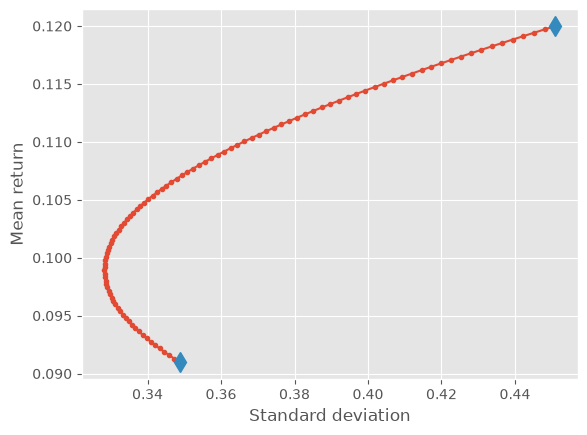

In [19]:
# TO-DO: Plot the 100 portfolios and the two initial portfolios
plt.plot(stds, means, ".-")
plt.plot([sigma_x, sigma_y], [mu_x, mu_y], "d", markersize=10)

plt.xlabel("Standard deviation")
plt.ylabel("Mean return")
plt.show()


Generate a new figure that also includes the four individual assets.

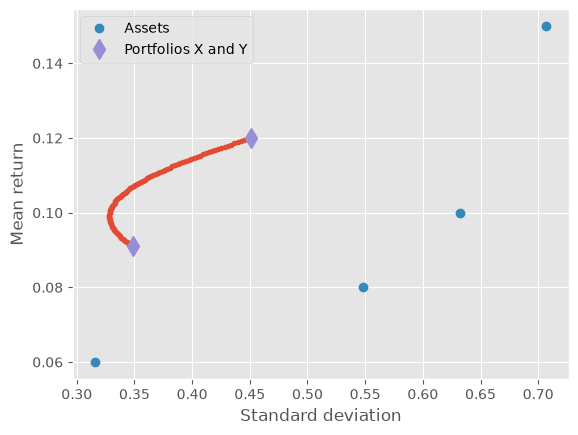

In [20]:
# TO-DO: Generate the figure again, adding the four individual assets
plt.plot(stds, means, ".-")
plt.plot(np.sqrt(np.diag(covariance_matrix)), mean_returns, "o", label="Assets")
plt.plot(
    [sigma_x, sigma_y],
    [mu_x, mu_y],
    "d",
    markersize=10,
    label="Portfolios X and Y",
)

plt.xlabel("Standard deviation")
plt.ylabel("Mean return")
plt.legend()
plt.show()


---

### Exercise 5

Generate 10,000 random portfolios, calculate their mean returns and standard deviations, and plot them together with the previous figure.

In [21]:
num_portfolios = 10000
num_assets = 4

# TO-DO: Generate 10,000 random portfolios
rng = np.random.default_rng(42)

weights = rng.random(size=(num_portfolios, num_assets))
weights = weights / weights.sum(axis=1, keepdims=True)

weights.shape


(10000, 4)

In [22]:
# TO-DO: Calculate portfolio returns and standard deviations
portfolio_returns = weights @ mean_returns

portfolio_stds = np.sqrt(
    np.diag(weights @ covariance_matrix @ weights.T)
)


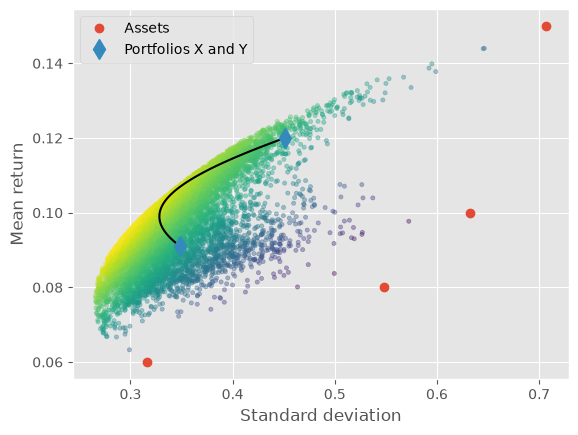

In [23]:
# TO-DO: Add the 10,000 portfolios to the previous figure
plt.scatter(
    portfolio_stds,
    portfolio_returns,
    c=portfolio_returns / portfolio_stds,
    marker=".",
    alpha=0.4,
)

plt.plot(stds, means, color="black")
plt.plot(np.sqrt(np.diag(covariance_matrix)), mean_returns, "o", label="Assets")
plt.plot(
    [sigma_x, sigma_y],
    [mu_x, mu_y],
    "d",
    markersize=10,
    label="Portfolios X and Y",
)

plt.xlabel("Standard deviation")
plt.ylabel("Mean return")
plt.legend()
plt.show()
